# Unemployment and crime in Polish voivodeships: analysis

In this notebook I look at how unemployment and crime changed in 2014-2024
and check if voivodeships with higher unemployment also have more crime.

Data: `data/processed/` (prepared in `01_cleaning.ipynb`).

In [1]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
from pathlib import Path
from adjustText import adjust_text

In [2]:
read_path = Path("../data/processed")
crimes = pd.read_csv(read_path/"crimes.csv",dtype={"unit_id":str})
crimes.head()

,unit_id,voivodeship,year,category,crime_count,crimes_per_1000
0,011200000000,MAŁOPOLSKIE,2014,criminal,51429,15.29
1,011200000000,MAŁOPOLSKIE,2014,economic,13625,4.05
2,011200000000,MAŁOPOLSKIE,2014,life_health,1608,0.48
3,011200000000,MAŁOPOLSKIE,2014,property,38955,11.58
4,011200000000,MAŁOPOLSKIE,2014,road,6309,1.88


In [3]:
unemployed = pd.read_csv(read_path/"unemployment.csv",dtype={"unit_id":str})
unemployed.head()

,unit_id,voivodeship,year,population,unemployment_rate
0,011200000000,MAŁOPOLSKIE,2014,3368336,9.7
1,011200000000,MAŁOPOLSKIE,2015,3372618,8.3
2,011200000000,MAŁOPOLSKIE,2016,3382260,6.6
3,011200000000,MAŁOPOLSKIE,2017,3391380,5.3
4,011200000000,MAŁOPOLSKIE,2018,3400577,4.7


In [4]:
poland = pd.read_csv(read_path/"poland.csv",dtype={"unit_id":str})
poland.head()

,year,crimes_total_per_1000,unemployment_rate
0,2014,22.55,11.4
1,2015,20.80,9.7
2,2016,19.48,8.2
3,2017,19.62,6.6
4,2018,19.99,5.8


### Do the categories add up to total?


In [5]:
crime_test=crimes[(crimes["voivodeship"]==("MAŁOPOLSKIE")) & (crimes["year"]==2014)].copy()

suma=0
total=0
for idx,row in crime_test.iterrows():
    if row["category"]!="total":
        suma+=row["crime_count"]
    else:
        total = row["crime_count"]
print(f"sum={suma}, total={total}")

sum=111926, total=73687


In [6]:
crime_test

,unit_id,voivodeship,year,category,crime_count,crimes_per_1000
0,011200000000,MAŁOPOLSKIE,2014,criminal,51429,15.29
1,011200000000,MAŁOPOLSKIE,2014,economic,13625,4.05
2,011200000000,MAŁOPOLSKIE,2014,life_health,1608,0.48
3,011200000000,MAŁOPOLSKIE,2014,property,38955,11.58
4,011200000000,MAŁOPOLSKIE,2014,road,6309,1.88
5,011200000000,MAŁOPOLSKIE,2014,total,73687,21.90


I checked one voivodeship and year (Małopolskie 2014):
the sum of the 5 categories is 111,926, but `total` is only 73,687.
So the categories overlap and one crime can be counted in more than one of them.
Because of this I never add categories together, and for overall crime I always use `total`.

## 1. Crime in Poland over time

To get the rate for the whole country I can't just take the average of the voivodeship rates,
because voivodeships have very different populations.
Instead I add up all crimes and all people for each year:
`rate = sum of crimes / sum of population * 1000`

In [7]:
total_crime = crimes[crimes["category"] == "total"].groupby("year")[["crime_count"]].sum()
total_crime

,crime_count
year,
2014,867855
2015,799779
2016,748459
2017,753963
2018,768049
2019,796557
2020,765408
2021,820846
2022,862432


In [8]:
total_population = unemployed.groupby("year")[["population"]].sum()
total_population

,population
year,
2014,38478602
2015,38437239
2016,38432992
2017,38433558
2018,38411148
2019,38382576
2020,38088564
2021,37907704
2022,37766327


In [9]:
merged = total_crime.merge(total_population,on="year")
merged["crimes_per_1000"] = round(merged["crime_count"]/merged["population"]*1000,2)
merged

,crime_count,population,crimes_per_1000
year,,,
2014,867855,38478602,22.55
2015,799779,38437239,20.81
2016,748459,38432992,19.47
2017,753963,38433558,19.62
2018,768049,38411148,20.00
2019,796557,38382576,20.75
2020,765408,38088564,20.10
2021,820846,37907704,21.65
2022,862432,37766327,22.84


In [10]:
check_pl = merged.reset_index().merge(poland, on="year")
check_pl["diff"] = check_pl["crimes_per_1000"] - check_pl["crimes_total_per_1000"]
check_pl[["year", "crimes_per_1000", "crimes_total_per_1000", "diff"]]

,year,crimes_per_1000,crimes_total_per_1000,diff
0,2014,22.55,22.55,0.00
1,2015,20.81,20.80,0.01
2,2016,19.47,19.48,-0.01
3,2017,19.62,19.62,0.00
4,2018,20.00,19.99,0.01
5,2019,20.75,20.75,0.00
6,2020,20.10,20.05,0.05
7,2021,21.65,21.61,0.04
8,2022,22.84,22.80,0.04
9,2023,21.04,21.01,0.03


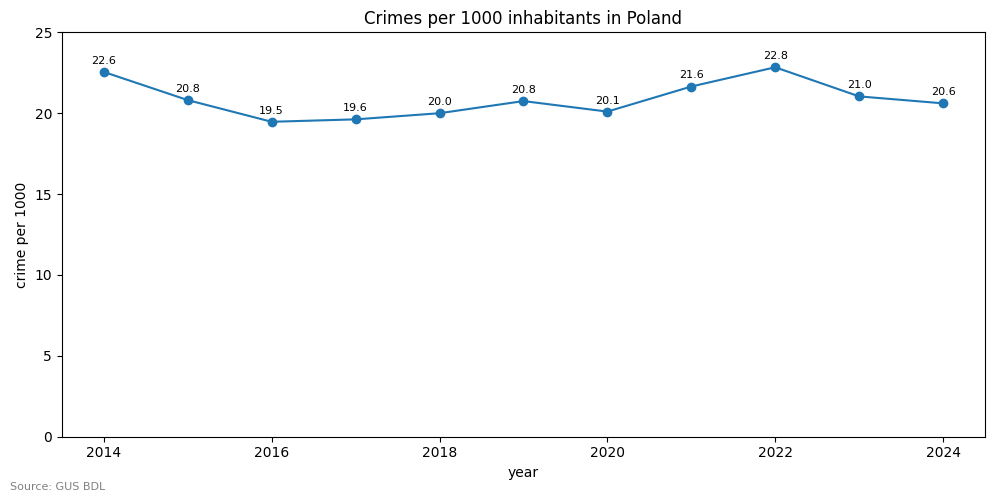

In [11]:
fig, ax = plt.subplots(figsize=(10, 5))

x = merged.index
y = merged["crimes_per_1000"]

ax.plot(x,y,marker="o")
ax.set_title("Crimes per 1000 inhabitants in Poland")
ax.set_xlabel("year")
ax.set_ylabel("crime per 1000")
ax.set_ylim(0, 25)
for year, row in merged.iterrows():
    ax.text(year, row["crimes_per_1000"] + 0.5,   
             f"{row['crimes_per_1000']:.1f}", ha="center", fontsize=8)
    
fig.text(0.01,0.01,"Source: GUS BDL",fontsize=8, color="gray")

plt.tight_layout()
save_img_path = Path("../images")
fig.savefig(save_img_path/"01_crime_poland.png")

I compared my rates with the official numbers for the whole country from GUS. In 2014-2019 they are the same,
and from 2020 mine are about 0.04 higher, probably because GUS recalculated the population after 2021.
So adding up crimes and population is the right way to get the rate for the whole country.

**Conclusion:** Crime per 1000 inhabitants went down from 22.6 in 2014 to 19.5 in 2016,
and then slowly went up until 2019. In 2020 there was a small drop, maybe because of the pandemic
(lockdowns, fewer people outside), but this data can't show why. In 2021-2022 crime went up again,
and 2022 was the highest year in the whole period (22.8). After that it went down.
Overall the changes are not big - all years are between about 19.5 and 23.

## 2. Unemployment in Poland over time


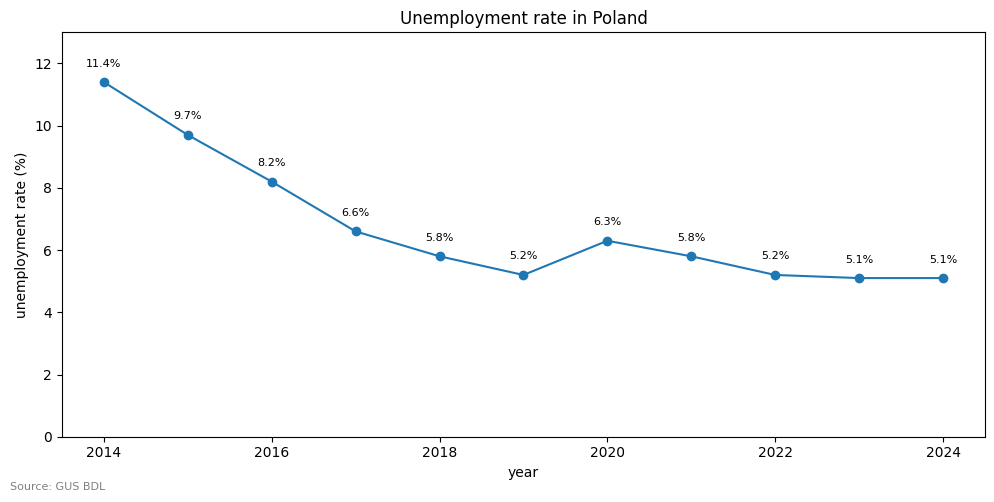

In [12]:
fig,ax = plt.subplots(figsize=(10,5))

x=poland["year"]
y=poland["unemployment_rate"]

ax.plot(x,y,marker="o")

ax.set_title("Unemployment rate in Poland")
ax.set_xlabel("year")
ax.set_ylabel("unemployment rate (%)")
ax.set_ylim(0,13)

for _, row in poland.iterrows():
    ax.text(row["year"], row["unemployment_rate"] + 0.5,   
             f"{row['unemployment_rate']:.1f}%", ha="center", fontsize=8)
    
fig.text(0.01,0.01,"Source: GUS BDL",fontsize=8, color="gray")

plt.tight_layout()
fig.savefig(save_img_path/"02_unemployment_poland.png")

**Conclusion:** Unemployment went down a lot, from 11.4% in 2014 to 5.2% in 2019.
In 2020, the pandemic year, it went up to 6.3%, and then it went down again to 5.1% in 2023-2024.

### Comparing both charts

In 2014-2016 both unemployment and crime went down. But later they often moved in opposite directions:
in 2020 unemployment went up while crime went down, and in 2021-2022 unemployment went down
while crime went up to its highest level. So for the whole country there is no clear
"more unemployment = more crime" pattern. Also, two lines going down at the same time don't prove
they are connected, because many other things changed in Poland in these years.

## 3. Comparing voivodeships

I use crimes per 1000 inhabitants, not the number of crimes. Big voivodeships like Mazowieckie
have more crimes just because more people live there, so the raw numbers would mostly show the size of the voivodeship.

In [13]:
# crime
ranking = crimes[(crimes["category"] == "total") & (crimes["year"].isin([2014, 2024]))]
ranking = ranking.pivot(
    index="voivodeship", 
    columns="year", 
    values="crimes_per_1000"
)
ranking = ranking.rename(columns={2014:"c2014",2024:"c2024"})

# unemployment rate
ranking2 = unemployed[unemployed["year"].isin([2014, 2024])]
ranking2 = ranking2.pivot(
    index="voivodeship", 
    columns="year", 
    values="unemployment_rate"
)
ranking2 = ranking2.rename(columns={2014:"u2014",2024:"u2024"})


both = ranking.merge(ranking2,on="voivodeship")
both.columns.name = None
both.index = both.index.str.title()
both = both.sort_index(ascending=False,key=lambda s: s.str.upper().str.replace("Ł", "L{").str.replace("Ś", "S{"))
both

,c2014,c2024,u2014,u2024
voivodeship,,,,
Zachodniopomorskie,25.36,20.33,15.5,6.8
Wielkopolskie,22.04,18.55,7.6,2.9
Warmińsko-Mazurskie,21.08,20.74,18.7,8.4
Świętokrzyskie,20.13,15.52,14.1,7.6
Śląskie,28.60,24.24,9.6,3.6
Pomorskie,23.81,21.47,11.1,4.6
Podlaskie,15.51,14.69,12.9,7.0
Podkarpackie,13.11,11.75,14.6,8.7
Opolskie,22.92,17.01,11.8,5.9


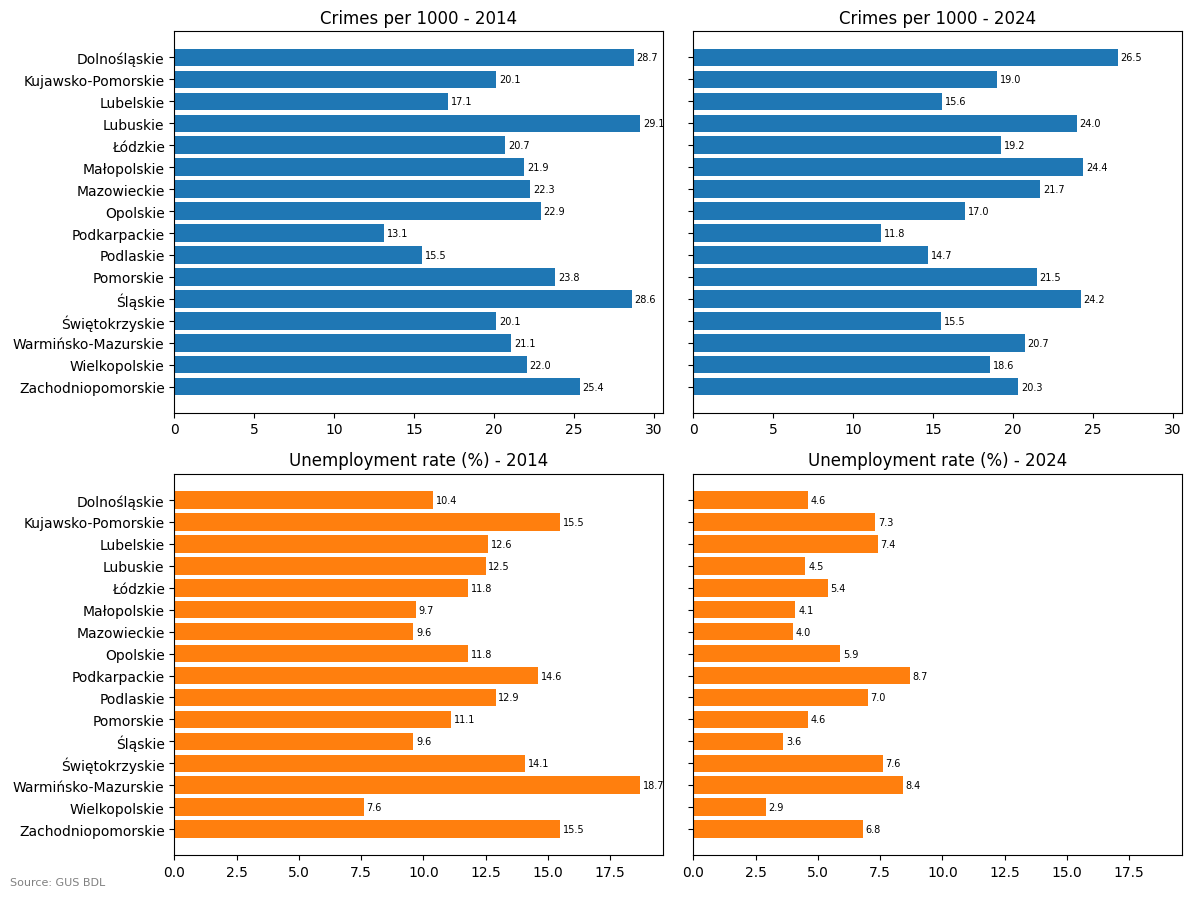

In [14]:
fig,axes =plt.subplots(2,2,figsize=(12,9),sharex="row",sharey=True)


# top left: crime 2014
bars00 = axes[0, 0].barh(both.index, both["c2014"], color="tab:blue")
axes[0, 0].bar_label(bars00, fmt="%.1f", fontsize=7, padding=2)
axes[0, 0].set_title("Crimes per 1000 - 2014")

# top right: crime 2024
bars01 = axes[0, 1].barh(both.index, both["c2024"], color="tab:blue")
axes[0, 1].bar_label(bars01, fmt="%.1f", fontsize=7, padding=2)
axes[0, 1].set_title("Crimes per 1000 - 2024")

# bottom left: unemployment 2014
bars10 = axes[1, 0].barh(both.index, both["u2014"], color="tab:orange")
axes[1, 0].bar_label(bars10, fmt="%.1f", fontsize=7, padding=2)
axes[1, 0].set_title("Unemployment rate (%) - 2014")

# bottom right: unemployment 2024
bars11 = axes[1, 1].barh(both.index, both["u2024"], color="tab:orange")
axes[1, 1].bar_label(bars11, fmt="%.1f", fontsize=7, padding=2)
axes[1, 1].set_title("Unemployment rate (%) - 2024")

fig.text(0.01, 0.01, "Source: GUS BDL", fontsize=8, color="gray")

plt.tight_layout()
fig.savefig(save_img_path / "03_voivodeships_2014_2024.png")

The chart shows crime and unemployment in every voivodeship in 2014 and 2024.
The voivodeships are in alphabetical order, so it's easy to compare the same voivodeship on all four charts.

**Conclusion:** The voivodeships with the most crime in 2024 (Dolnośląskie, Małopolskie, Śląskie)
are not the ones with the highest unemployment (Podkarpackie, Warmińsko-Mazurskie, Świętokrzyskie).
Podkarpackie is the most interesting example - it has the highest unemployment and at the same time the lowest crime.
Comparing only 2014 and 2024, total crime went down in every voivodeship except Małopolskie (21.9 -> 24.4).
Unemployment went down everywhere, in most voivodeships by half or more, but the order of voivodeships
stayed almost the same. Wielkopolskie, Śląskie, Mazowieckie and Małopolskie had the lowest unemployment
in both years, and Warmińsko-Mazurskie, Podkarpackie and Świętokrzyskie were among the highest in both years.

## 4. Is higher unemployment connected with more crime?

To check this I look at one year at a time - here 2014 and 2024. Over these 10 years unemployment went down in every voivodeship,
so if I put all years together I would be comparing, for example, Śląskie in 2014 with Śląskie in 2024, and the difference between them comes mostly from time passing, not from the voivodeship.
In one year all voivodeships are in the same situation, so the comparison is fair.

I also calculate the correlation, which goes from -1 to 1.
A value close to 1 would mean that more unemployment goes together with more crime,
close to -1 that more unemployment goes together with less crime, and close to 0 that there is no clear connection.

In [15]:
corr_2014 = both["u2014"].corr(both["c2014"])
corr_2024 = both["u2024"].corr(both["c2024"])
print(f"correlation 2014: {corr_2014:.2f}")
print(f"correlation 2024: {corr_2024:.2f}")

correlation 2014: -0.32
correlation 2024: -0.68


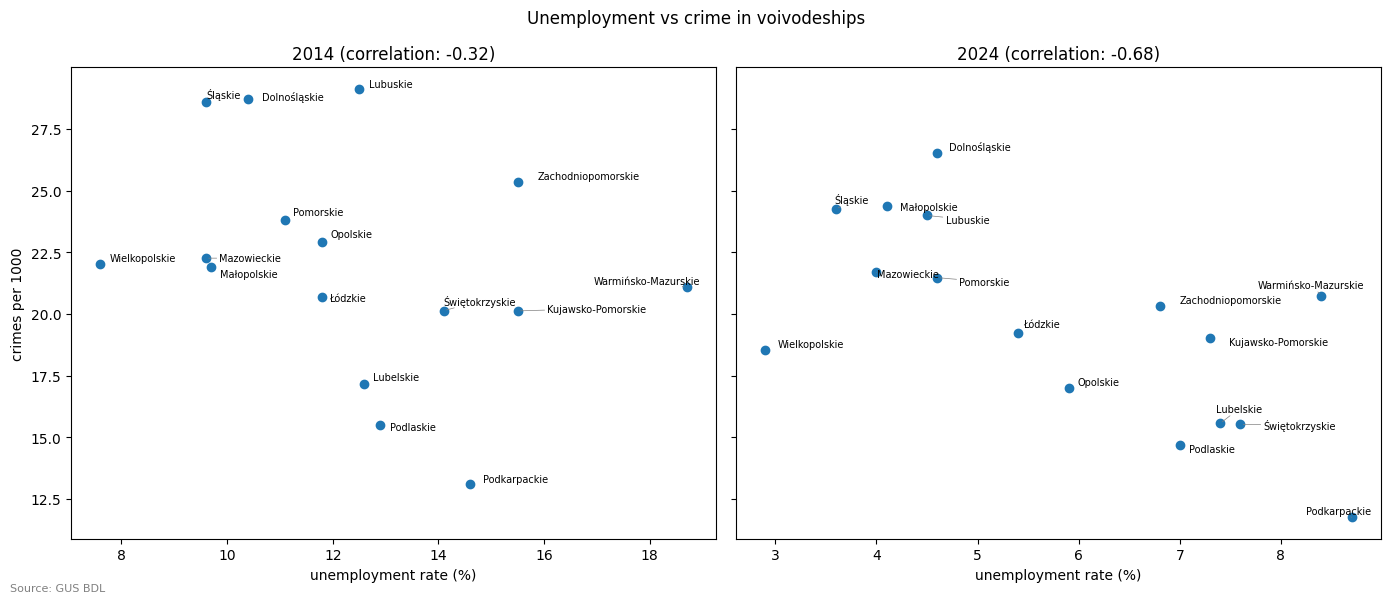

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)

# left: 2014
axes[0].scatter(both["u2014"], both["c2014"])
texts_2014 = []
for name, row in both.iterrows():
    texts_2014.append(axes[0].text(row["u2014"], row["c2014"], name, fontsize=7))
adjust_text(texts_2014, ax=axes[0], arrowprops=dict(arrowstyle="-", color="gray", lw=0.5))
axes[0].set_title(f"2014 (correlation: {corr_2014:.2f})")
axes[0].set_xlabel("unemployment rate (%)")
axes[0].set_ylabel("crimes per 1000")

# right: 2024
axes[1].scatter(both["u2024"], both["c2024"])
texts_2024 = []
for name, row in both.iterrows():
    texts_2024.append(axes[1].text(row["u2024"], row["c2024"], name, fontsize=7))
adjust_text(texts_2024, ax=axes[1], arrowprops=dict(arrowstyle="-", color="gray", lw=0.5))
axes[1].set_title(f"2024 (correlation: {corr_2024:.2f})")
axes[1].set_xlabel("unemployment rate (%)")

fig.suptitle("Unemployment vs crime in voivodeships")
fig.text(0.01, 0.01, "Source: GUS BDL", fontsize=8, color="gray")

plt.tight_layout()
fig.savefig(save_img_path / "04_scatter_2014_2024.png")

**Conclusion:** The correlation is negative: -0.32 in 2014 and -0.68 in 2024. So voivodeships with higher
unemployment have less crime per 1000 inhabitants, not more, and this got stronger over the 10 years.
Podkarpackie, Podlaskie and Lubelskie have high unemployment and low crime, while Śląskie, Dolnośląskie
and Małopolskie have low unemployment and a lot of crime.

This doesn't mean that unemployment lowers crime. A possible explanation is a third factor:
voivodeships with big cities (Wrocław, Kraków, Katowice) have more jobs, but also more people,
traffic and tourists, so more chances for crime. My data can't check this.

### Crime categories

Total crime has a negative correlation with unemployment. But maybe some types of crime
behave differently - for example crimes against property could be more common where people have less money.
So I made the same chart for every category separately.

In [17]:
def plot_categories(year):
    all_crimes = crimes[crimes["year"]==year]
    all_crimes_unp = all_crimes.merge(unemployed[["unit_id","year","unemployment_rate"]],on=["unit_id","year"])
    fig, axes = plt.subplots(2,3,figsize=(15,9),sharex=True)
    categories = crimes["category"].unique()
    for i, category in enumerate(categories):
        one_category = all_crimes_unp[all_crimes_unp["category"].isin([category])]
        ax = axes.flatten()[i]
        ax.scatter(one_category["unemployment_rate"],one_category["crimes_per_1000"])
        corr_ = one_category["unemployment_rate"].corr(one_category["crimes_per_1000"])
        ax.set_title(f"Crime - {category} (r = {corr_:.2f})")
        ax.set_xlabel("unemployment rate (%)")

    fig.suptitle(f"Unemployment vs crime types in voivodeships ({year})")
    fig.text(0.01, 0.01, "Source: GUS BDL", fontsize=8, color="gray")

    plt.tight_layout()
    fig.savefig(save_img_path / f"05_scatter_categories_{year}.png")



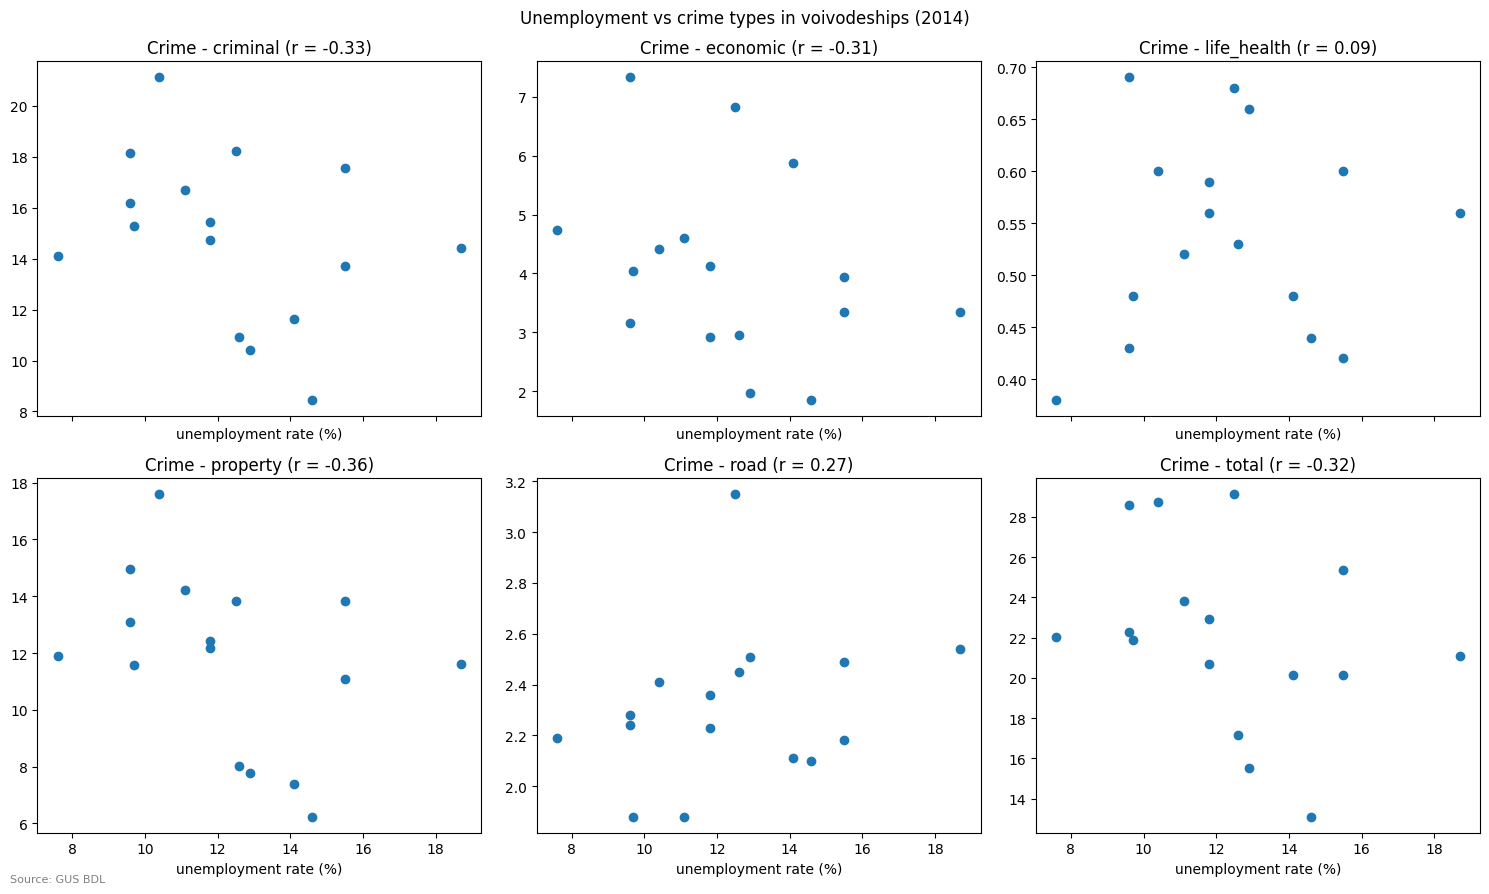

In [18]:
plot_categories(2014)

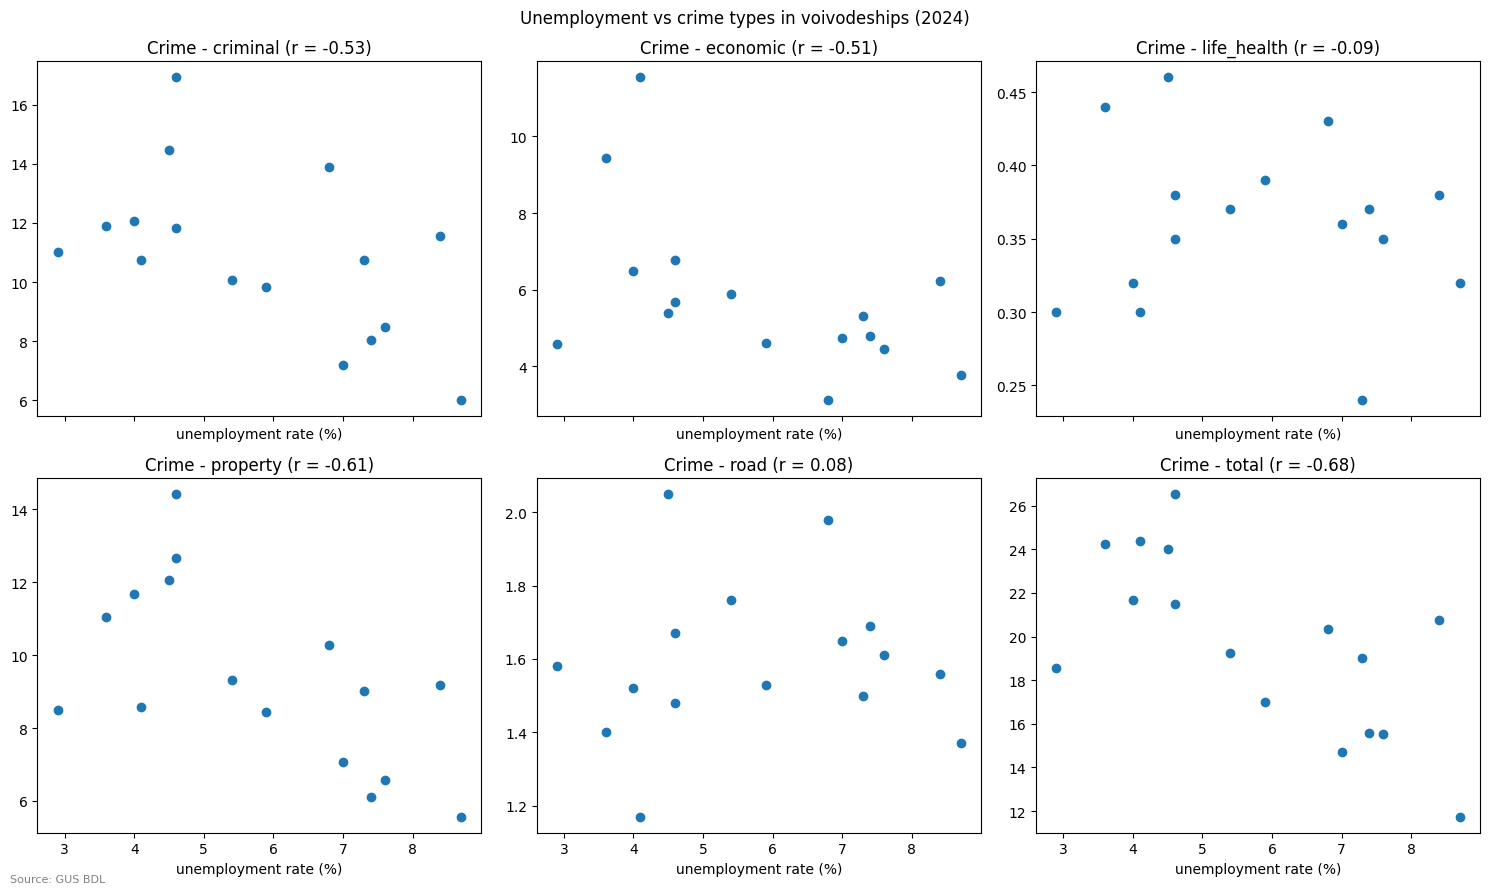

In [19]:
plot_categories(2024)

**Conclusion:** In 2024 most categories have a negative correlation with unemployment, like total crime.
The strongest is property crime (-0.61), so my idea that crimes against property would be more common
where unemployment is higher was wrong - it's the opposite. Thefts and burglaries are more common
in voivodeships with low unemployment, which fits the idea that big cities simply have more things to steal.
Road crimes (0.08) and crimes against life and health (-0.09) have almost no connection with unemployment.

In 2014 the pattern was the same, just weaker: total, property, criminal and economic crime
had correlations between -0.31 and -0.36. Road crime was slightly positive (0.27), but that's still weak.
By 2024 all the negative correlations got stronger.

### Correlation in every year

To check if the result is stable, I calculated the correlation between unemployment and crime
for every year and every category.

In [20]:
all_years = crimes.merge(unemployed[["unit_id","year","unemployment_rate"]],on=["unit_id","year"])

correlations=[]
for year in range(2014,2025):
    for category in crimes['category'].unique():
        one = all_years[(all_years["year"] == year) & (all_years["category"] == category)]
        corr = one["unemployment_rate"].corr(one["crimes_per_1000"])
        correlations.append({"year": year, "category": category, "correlation": corr})

correlations = pd.DataFrame(correlations)
print(correlations.shape)

corr_table = correlations.pivot(index="year", columns="category", values="correlation")
corr_table.round(2)

(66, 3)


category,criminal,economic,life_health,property,road,total
year,,,,,,
2014,-0.33,-0.31,0.09,-0.36,0.27,-0.32
2015,-0.43,-0.28,0.30,-0.48,0.24,-0.43
2016,-0.41,-0.61,0.25,-0.45,0.40,-0.49
2017,-0.48,-0.38,0.18,-0.51,0.38,-0.54
2018,-0.45,-0.35,-0.01,-0.56,0.39,-0.46
2019,-0.35,-0.54,-0.01,-0.63,0.38,-0.44
2020,-0.36,-0.27,0.07,-0.38,0.32,-0.41
2021,-0.58,-0.49,-0.02,-0.66,0.21,-0.64
2022,-0.61,-0.33,-0.04,-0.63,0.08,-0.60


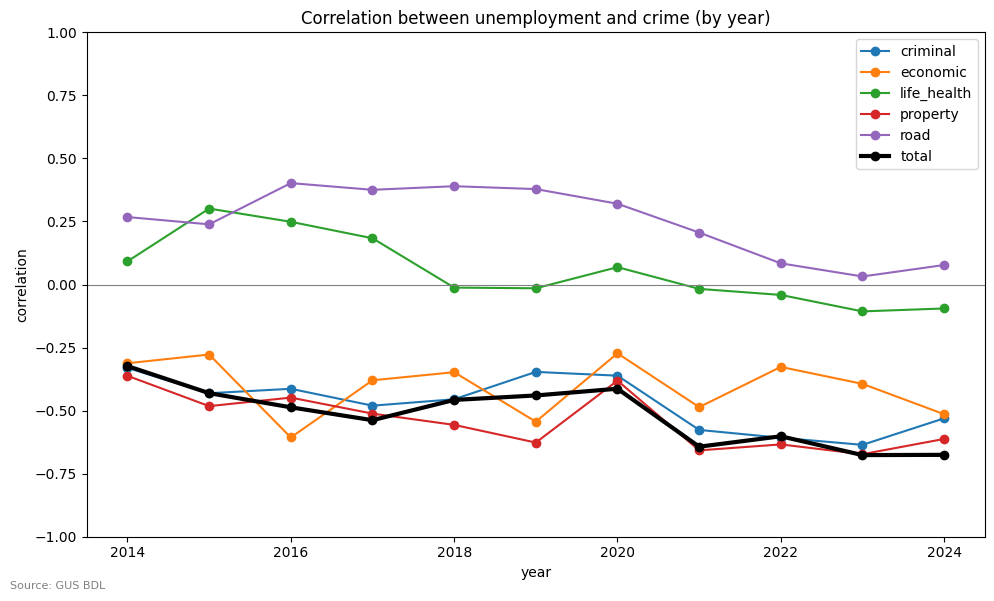

In [21]:
fig, ax = plt.subplots(figsize=(10, 6))

categories = crimes["category"].unique()
for category in categories:
    if category == "total":
        ax.plot(corr_table.index, corr_table[category], marker="o", label=category, linewidth=3, color="black")
    else:
        ax.plot(corr_table.index, corr_table[category], marker="o", label=category, linewidth=1.5)
        
ax.axhline(0, color="gray", linewidth=0.8)
ax.set_ylim(-1, 1)
ax.set_title("Correlation between unemployment and crime (by year)")
ax.set_xlabel("year")
ax.set_ylabel("correlation")
ax.legend()

fig.text(0.01, 0.01, "Source: GUS BDL", fontsize=8, color="gray")

plt.tight_layout()
fig.savefig(save_img_path / "06_correlation_by_year.png")

**Conclusion:** The categories split into two groups. Total, criminal, property and economic crime
have a negative correlation in every year, so this is not a one-year accident.

Road crime is the only category with a positive correlation in all years (up to 0.40), but after 2020
it went down to almost zero. Crimes against life and health were slightly positive until 2017
and after that stayed close to zero.

In 2020 all the negative correlations got weaker, and in 2021 they got much stronger and stayed like that.
This could be connected with the pandemic, but my data can't show that.

## 5. Unusual values

While cleaning the data I noticed two values that look much higher than the rest:
Śląskie in 2022 and Zachodniopomorskie in 2019. Małopolskie is also interesting,
because it was the only voivodeship where crime went up from 2014 to 2024.
I want to check what happened there.

In [22]:
voi_trend = crimes[crimes["category"] == "total"]
voi_trend = voi_trend.pivot(
    index="year", 
    columns="voivodeship", 
    values="crimes_per_1000"
)
print(voi_trend.shape)
voi_trend.head()

(11, 16)


voivodeship,DOLNOŚLĄSKIE,KUJAWSKO-POMORSKIE,LUBELSKIE,LUBUSKIE,MAZOWIECKIE,MAŁOPOLSKIE,OPOLSKIE,PODKARPACKIE,PODLASKIE,POMORSKIE,WARMIŃSKO-MAZURSKIE,WIELKOPOLSKIE,ZACHODNIOPOMORSKIE,ŁÓDZKIE,ŚLĄSKIE,ŚWIĘTOKRZYSKIE
year,,,,,,,,,,,,,,,,
2014,28.73,20.12,17.14,29.13,22.26,21.90,22.92,13.11,15.51,23.81,21.08,22.04,25.36,20.70,28.60,20.13
2015,27.33,18.60,15.39,26.43,21.06,20.56,19.95,12.92,14.68,21.28,18.80,19.81,23.21,19.34,25.59,19.64
2016,25.73,17.82,14.62,22.38,20.20,21.50,20.01,11.02,14.36,19.93,18.76,17.74,21.00,18.50,23.18,15.12
2017,25.10,17.99,14.59,23.00,19.35,24.34,19.95,13.97,13.89,19.02,17.07,16.50,19.88,17.76,24.53,16.87
2018,25.76,20.96,16.11,24.77,20.92,22.00,17.54,11.39,14.49,19.49,17.61,17.18,23.48,17.49,24.27,16.29


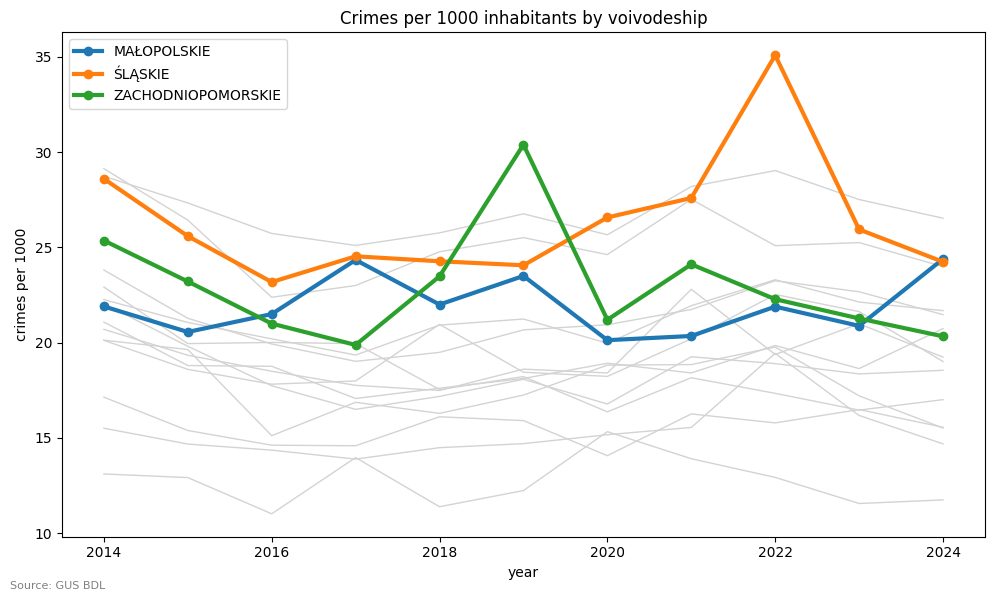

In [23]:
voi = ["ŚLĄSKIE","ZACHODNIOPOMORSKIE","MAŁOPOLSKIE"]

fig, ax = plt.subplots(figsize=(10, 6))

all_voi = crimes["voivodeship"].unique()
for v in all_voi:
    if v in voi:
        ax.plot(voi_trend.index, voi_trend[v], marker="o", label=v, linewidth=3,zorder=3)
    else:
        ax.plot(voi_trend.index, voi_trend[v], linewidth=1, color="lightgray")
        
ax.set_title("Crimes per 1000 inhabitants by voivodeship")
ax.set_xlabel("year")
ax.set_ylabel("crimes per 1000")
ax.legend()

fig.text(0.01, 0.01, "Source: GUS BDL", fontsize=8, color="gray")

plt.tight_layout()
fig.savefig(save_img_path / "07_unusual_values.png")

In [24]:
def categories_by_year(voivodeship):
    cr = crimes[crimes["voivodeship"]==voivodeship]
    cr = cr.pivot(
        index = "year",
        columns = "category",
        values = "crimes_per_1000"
    )
    return cr

In [25]:
categories_by_year("ŚLĄSKIE")

category,criminal,economic,life_health,property,road,total
year,,,,,,
2014,18.15,7.33,0.69,14.95,2.28,28.60
2015,15.77,6.91,0.61,14.13,2.02,25.59
2016,14.32,6.09,0.63,12.05,1.84,23.18
2017,13.94,8.05,0.65,12.21,1.60,24.53
2018,14.90,6.87,0.64,11.01,1.54,24.27
2019,14.76,6.68,0.55,11.59,1.68,24.06
2020,13.92,10.37,0.45,13.38,1.43,26.57
2021,14.22,10.66,0.43,15.57,1.67,27.59
2022,14.39,17.79,0.44,14.31,1.68,35.08


In [26]:
categories_by_year("ZACHODNIOPOMORSKIE")


category,criminal,economic,life_health,property,road,total
year,,,,,,
2014,17.56,3.94,0.60,13.85,2.49,25.36
2015,15.08,4.57,0.58,11.61,2.24,23.21
2016,14.59,3.03,0.52,10.67,2.06,21.00
2017,14.03,2.61,0.60,9.09,2.14,19.88
2018,16.15,3.89,0.57,9.79,2.07,23.48
2019,22.30,4.70,0.60,10.91,2.45,30.39
2020,14.96,3.09,0.52,10.27,2.29,21.20
2021,16.89,3.58,0.49,10.48,2.58,24.11
2022,15.77,2.98,0.45,10.86,2.47,22.28


In [27]:
categories_by_year("MAŁOPOLSKIE")

category,criminal,economic,life_health,property,road,total
year,,,,,,
2014,15.29,4.05,0.48,11.58,1.88,21.90
2015,13.40,4.57,0.35,10.34,1.66,20.56
2016,13.15,5.84,0.36,9.33,1.59,21.50
2017,12.99,9.11,0.40,9.56,1.46,24.34
2018,12.37,7.58,0.35,8.52,1.38,22.00
2019,12.31,9.02,0.38,11.04,1.44,23.50
2020,10.92,7.18,0.29,7.46,1.24,20.13
2021,10.72,7.03,0.25,9.19,1.28,20.35
2022,12.25,6.74,0.26,10.41,1.39,21.89


**Conclusion:** Śląskie 2022 and Zachodniopomorskie 2019 are one-year jumps - crime goes up for one year
and goes back to the normal level in the next year. In Śląskie almost the whole jump comes from
economic crime (10.66 -> 17.79 -> 9.58). In Zachodniopomorskie it comes from criminal offences
(16.15 -> 22.30 -> 14.96), but not from property crime or crimes against life and health,
so it was some other type of crime that my data doesn't show. Jumps like this are probably caused by
one big case with a lot of crimes registered at once, not by a real change in the region.

Małopolskie is different. Its total crime didn't grow every year - it went up and down between about 20 and 24,
and most of the "increase" from 2014 to 2024 happened in 2024 alone. Looking at the categories,
economic crime almost tripled (4.05 -> 11.54), while criminal offences went down (15.29 -> 10.73).
So in Małopolskie only economic crime went up, other crime went down like in the rest of Poland.

This also shows that comparing only the first and the last year can be misleading.

## 6. Change over 10 years

Here I check a different question: did crime go down more in voivodeships where unemployment went down more?
This way I compare each voivodeship with itself, so things that don't change much
(like having a big city or a lot of tourists) don't matter.

I don't compare just 2014 and 2024, because one unusual year (like Małopolskie in 2024) could change the result a lot.
Instead I take the median of the first 3 years (2014-2016) and the last 3 years (2022-2024).
The median ignores one unusual value, for example Śląskie in 2022.

At first I tried a straight trend line through all 11 years, but crime in Poland went down and then up again
(like the letter U), so a straight line didn't describe it well.

In [28]:
total_all = all_years[all_years["category"] == "total"]

start = total_all[total_all["year"].between(2014, 2016)]
start = start.groupby("voivodeship")[["unemployment_rate", "crimes_per_1000"]].median()

end = total_all[total_all["year"].between(2022, 2024)]
end = end.groupby("voivodeship")[["unemployment_rate", "crimes_per_1000"]].median()

change = end - start
change.index = change.index.str.title()
change.round(2)

,unemployment_rate,crimes_per_1000
voivodeship,,
Dolnośląskie,-4.0,0.18
Kujawsko-Pomorskie,-5.9,3.03
Lubelskie,-4.1,0.40
Lubuskie,-6.1,-1.34
Mazowieckie,-4.3,1.07
Małopolskie,-4.1,0.39
Opolskie,-4.2,-3.00
Podkarpackie,-4.5,-1.17
Podlaskie,-4.8,1.50


In [29]:
corr_change = change["unemployment_rate"].corr(change["crimes_per_1000"])
print(f"correlation: {corr_change:.2f}")



correlation: -0.15


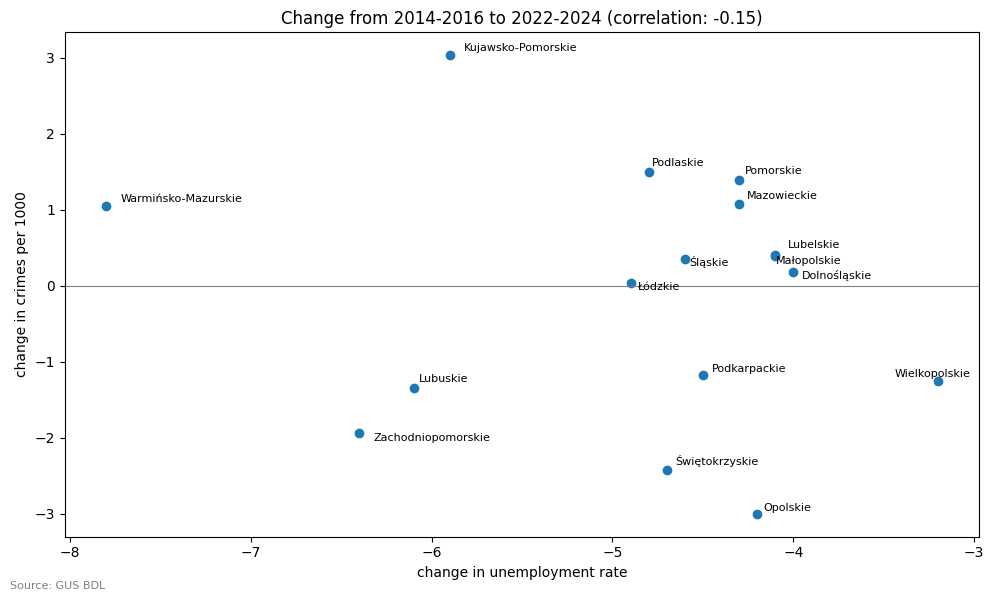

In [30]:
fig, ax = plt.subplots(figsize=(10, 6))

ax.scatter(change["unemployment_rate"], change["crimes_per_1000"])

texts = []
for name, row in change.iterrows():
    texts.append(ax.text(row["unemployment_rate"], row["crimes_per_1000"], name, fontsize=8))
adjust_text(texts, ax=ax, arrowprops=dict(arrowstyle="-", color="gray", lw=0.5))

ax.axhline(0, color="gray", linewidth=0.8)

ax.set_title(f"Change from 2014-2016 to 2022-2024 (correlation: {corr_change:.2f})")
ax.set_xlabel("change in unemployment rate")
ax.set_ylabel("change in crimes per 1000")

fig.text(0.01, 0.01, "Source: GUS BDL", fontsize=8, color="gray")

plt.tight_layout()
fig.savefig(save_img_path / "08_change_2014_2024.png")

**Conclusion:** The correlation is -0.15, so there is almost no connection between how much unemployment
went down and how crime changed. If unemployment caused crime, the voivodeships with the biggest drop
in unemployment should have the biggest drop in crime. They don't: Warmińsko-Mazurskie had the biggest drop
in unemployment (-7.8) and crime went up (+1.05), while Wielkopolskie had the smallest drop (-3.2)
and crime went down (-1.26).

Also, in the whole of Poland unemployment went down by more than half, but crime stayed almost the same
(median 20.8 in 2014-2016 and 21.0 in 2022-2024). The drop from 2014 to 2024 that I saw earlier
was mostly because 2014 was a high year.

## Summary

I wanted to check if voivodeships with higher unemployment also have more crime.
I used data from GUS for 2014-2024 and compared crime per 1000 inhabitants, not the number of crimes,
so that big and small voivodeships can be compared fairly.

In the whole country unemployment went down by more than half (from 11.4% to 5.1%),
but crime stayed almost the same - all years were between about 19.5 and 23 crimes per 1000.
So a big drop in unemployment did not bring a drop in crime.

When I compared voivodeships with each other, the correlation was negative in every year
(from -0.32 in 2014 to -0.68 in 2024). Voivodeships with higher unemployment, like Podkarpackie,
have less crime, and voivodeships with low unemployment, like Dolnośląskie, Śląskie and Małopolskie, have more.
Property crime showed this the most, and road crime and crimes against life and health
had almost no connection with unemployment. A possible reason is that regions with big cities
have both more jobs and more chances for crime, but my data can't check this.

When I compared how each voivodeship changed over 10 years, there was almost no connection (-0.15):
the voivodeships where unemployment went down the most didn't have a bigger drop in crime.

The unusual values in Śląskie (2022) and Zachodniopomorskie (2019) were one-year jumps,
probably caused by single big cases. Małopolskie was the only voivodeship where crime went up from 2014 to 2024, and this came from economic crime.

It's important to remember that correlation doesn't show what causes what - it only shows that two things go together. Also, the data only includes crimes registered by the police, not all crimes that happened, and GUS recalculated the population in 2021, so the rates before and after 2020 can differ a little.

**Final Conclusion:** in this data higher unemployment does not go together with more crime.
If anything, it's the opposite, but that is most likely because of other differences between regions,
not because of unemployment itself.
